# CS920 · Lab 4 (Week 5) — Learning dynamics by predicting the future

**50 minutes · PyTorch, NumPy, Matplotlib and scikit-learn · CPU only (no GPU required)**

In Lecture 7, we saw that clustering depends on the geometry induced by a representation. In Lecture 8, we saw that a training target can be constructed automatically from the data itself.

Today we combine those ideas on **time series** rather than images.

We will generate oscillating trajectories produced by three different update rules. The update-rule label will never be used to train the model. Instead, we will train a small network to predict the next observation and ask:

> **Does self-supervised prediction learn a representation in which the three kinds of dynamics become easier to cluster?**

By the end, you should be able to:

1. Explain why raw trajectory windows can have a poor geometry for clustering.
2. Turn an unlabelled time series into a self-supervised regression dataset.
3. Compare K-means in the raw space with K-means in a learnt representation.

*Task: Before running each piece of code, first predict what you will see. Then, after running, explain what you have seen.*

### Start JupyterLab (DCS desktop)

If you already have your CS920 environment:

```bash
module load cs920-python
cd ~/cs920
source venv/bin/activate
mkdir -p lab4
cp /modules/cs920/labs/lab4/lab4.ipynb ~/cs920/lab4/
cd ~/cs920/lab4
jupyter lab
```

Open `lab4.ipynb` in JupyterLab. Run cells in order (**Shift+Enter**).

This lab generates its own data: **no downloads**.


## 1. Same kind of signal, different dynamics (about 12 minutes)

Each trajectory follows a noisy second-order update rule(噪声二阶更新规则)

$$
\boxed{x_{t+1}=a_k x_t+b_k x_{t-1}+\epsilon_t,}
$$

where $k\in\{0,1,2\}$ is the **dynamical regime**. Different values of $(a_0,b_0), (a_1, b_1), (a_2, b_2)$ produce oscillations with different frequencies. Given data $x_0, x_1, ..., x_N$, we want to predict whether the dynamics correspond to regime 0, 1, or 2.
·
Each trajectory starts from a random pair of initial values $(x_0,x_1)$. Thus, even trajectories with the same update rule can begin in very different places and look quite different as raw vectors. 

The array `regime` stores which update rule generated each trajectory. **K-means and the neural network will never receive these labels.** We keep them only so that, after learning, we can inspect what structure was discovered.


Trajectories: (900, 80)


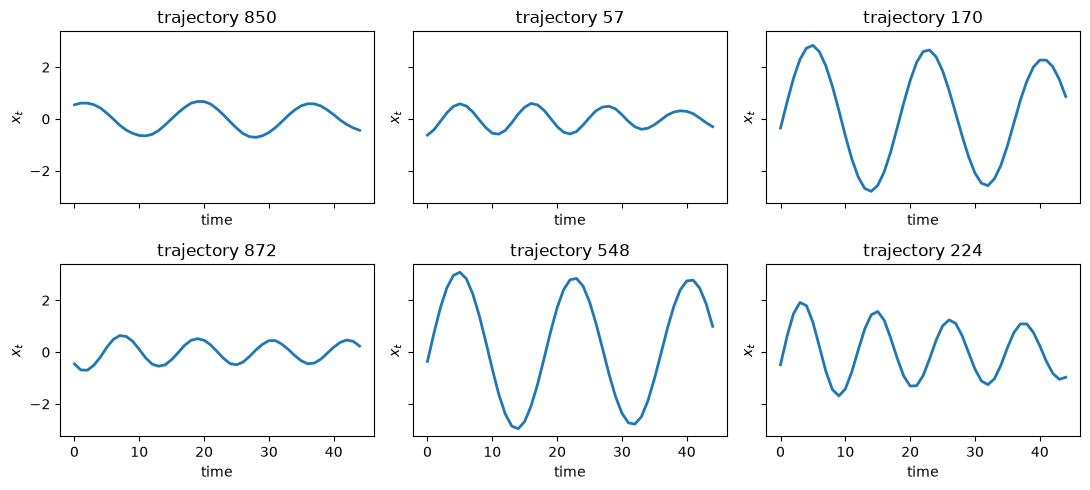

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.cluster import KMeans
from sklearn.metrics.cluster import contingency_matrix

# Keep this light for shared lab desktops.
torch.set_num_threads(min(2, torch.get_num_threads()))

SEED = 920

# Three fixed, stable second-order update rules.
# The pairs (a_0, b_0), (a_1, b_1), (a_2, b_2) define the dynamical regimes directly.
DYNAMICS = np.array([
    [1.8693517, -0.9900250],
    [1.6794733, -0.9702250],
    [1.3585781, -0.9506250],
], dtype=np.float32)

def make_trajectories(n=900, length=80, seed=SEED):
    rng = np.random.default_rng(seed)
    regime = np.repeat(np.arange(3), n // 3)
    rng.shuffle(regime)

    trajectories = np.zeros((n, length), dtype=np.float32)

    for i, k in enumerate(regime):
        a, b = DYNAMICS[k]

        # Random starting state, sampled independently of the regime.
        trajectories[i, 0] = rng.uniform(-1.0, 1.0)
        trajectories[i, 1] = rng.uniform(-1.0, 1.0)

        # Same update rule throughout this trajectory.
        for t in range(1, length - 1):
            trajectories[i, t + 1] = (
                a * trajectories[i, t]
                + b * trajectories[i, t - 1]
                + rng.normal(0, 0.015)
            )

    return trajectories, regime


trajectories, regime = make_trajectories()
print("Trajectories:", trajectories.shape)

# Look at six examples without showing their regimes.
rng = np.random.default_rng(12)
example_ids = rng.choice(len(trajectories), size=6, replace=False)

fig, axes = plt.subplots(2, 3, figsize=(11, 5), sharex=True, sharey=True)
for ax, i in zip(axes.flat, example_ids):
    ax.plot(trajectories[i, :45], lw=2)
    ax.set_title(f"trajectory {i}")
    ax.set_xlabel("time")
    ax.set_ylabel(r"$x_t$")
plt.tight_layout()
plt.show()


### K-means on raw trajectory windows

Treat the first 30 observations of each trajectory as a point in $\mathbb R^{30}$ and run ordinary K-means with $K=3$.

**Predict first:** Suppose two trajectories obey the same update rule but start from different values of $(x_0,x_1)$. Should their 30 raw values necessarily be close in Euclidean distance?

As in Lecture 7, cluster numbers are arbitrary. We therefore inspect a **contingency table** only after clustering. `purity` is a simple diagnostic: within each K-means cluster, take the majority true regime and count how many examples agree with it.


K-means on raw trajectory windows
rows = true regimes; columns = K-means clusters
[[123  95  82]
 [300   0   0]
 [300   0   0]]
purity = 0.530



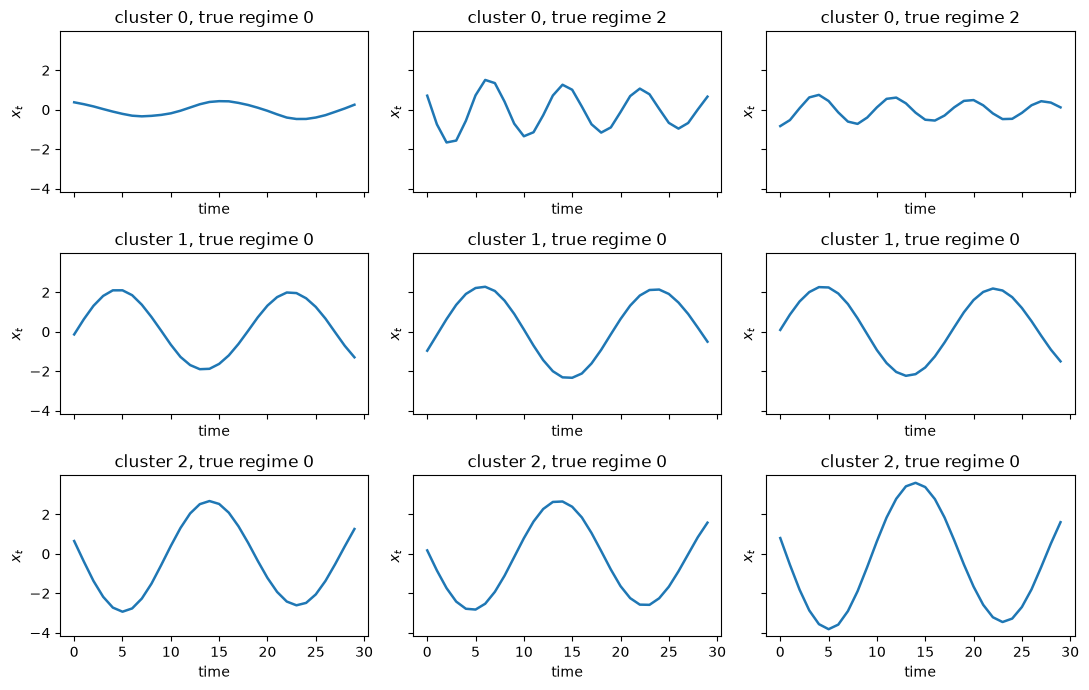

In [2]:
def cluster_report(true_regime, cluster_id, title):
    table = contingency_matrix(true_regime, cluster_id)
    purity = table.max(axis=0).sum() / table.sum()
    print(title)
    print("rows = true regimes; columns = K-means clusters")
    print(table)
    print(f"purity = {purity:.3f}\n")
    return purity


HISTORY = 30
X_raw = trajectories[:, :HISTORY]

raw_clusters = KMeans(n_clusters=3, n_init=20, random_state=0).fit_predict(X_raw)
raw_purity = cluster_report(regime, raw_clusters, "K-means on raw trajectory windows")

# Inspect a few members of each raw cluster.
fig, axes = plt.subplots(3, 3, figsize=(11, 7), sharex=True, sharey=True)
for cluster in range(3):
    members = np.flatnonzero(raw_clusters == cluster)[:3]
    for ax, i in zip(axes[cluster], members):
        ax.plot(X_raw[i], lw=1.8)
        ax.set_title(f"cluster {cluster}, true regime {regime[i]}")
        ax.set_xlabel("time")
        ax.set_ylabel(r"$x_t$")
plt.tight_layout()
plt.show()


**Stop and explain:**

- What variation is K-means seeing in the raw coordinates?
- Convince yourself that a poor result is evidence that this representation does not expose the features well enough.


## 2. Make a self-supervised regression problem (about 10 minutes)

We now ask the trajectory itself to provide the training target.

From a history window

$$
(x_{t-29},\ldots,x_t),
$$

we predict the next observation $x_{t+1}$.

We first split by whole trajectories, then create windows. That prevents windows from one validation trajectory leaking into the training set.



In [ ]:
STRIDE = 5

order = np.random.default_rng(42).permutation(len(trajectories))

# Split trajectories into training and validation splits
train_ids = order[:600]
val_ids = order[600:]


def make_prediction_pairs(trajectories, ids, history=HISTORY, stride=STRIDE):
    windows, targets = [], []

    for i in ids:
        x = trajectories[i]
        for t in range(history, len(x), stride):
            windows.append(x[t-history:t])
            targets.append(x[t])

    X = torch.tensor(np.asarray(windows), dtype=torch.float32)
    y = torch.tensor(np.asarray(targets), dtype=torch.float32).reshape(-1, 1)
    return X, y


X_train, y_train = make_prediction_pairs(trajectories, train_ids)
X_val, y_val = make_prediction_pairs(trajectories, val_ids)

assert X_train.shape == (6000, HISTORY), "Task A: expected 6000 training windows of length 30."
assert y_train.shape == (6000, 1), "Task A: expected one next-value target per window."
print("training pairs:", X_train.shape, y_train.shape)
print("validation pairs:", X_val.shape, y_val.shape)


## 3. A bottleneck for the dynamics (about 15 minutes)

A raw history contains two different kinds of information:

- the **current state** of the oscillator: where it is right now;
- the **dynamics**: the update rule that tells us how the state will evolve.

We will deliberately separate them.

The encoder reads the whole 30-step history and produces a two-dimensional code

$$
z=f_\theta(x_{t-29:t})=(z_1,z_2).
$$

The predictor is then given the last two observations directly and uses

$$
\boxed{\hat x_{t+1}=z_1x_t+z_2x_{t-1}.}
$$

So the bottleneck does **not** need to remember the current state: $x_t$ and $x_{t-1}$ are already available. To predict well across many trajectories with different starting values, the useful thing for $z$ to encode is the **update rule**.

This is an example of an **inductive bias**: the architecture expresses what kind of representation we hope the task will encourage, but the values of $z$ are learnt from prediction error alone.

Before training, the encoder is random. We will compare its representation with the one obtained after self-supervised learning.


In [ ]:
class DynamicsPredictor(nn.Module):
    def __init__(self, history=HISTORY):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(history, 32),
            nn.Tanh(),
            nn.Linear(32, 2),
        )

    def encode(self, x):
        # Remove overall scale before asking the encoder about the dynamics.
        scale = torch.sqrt(torch.mean(x ** 2, dim=1, keepdim=True) + 1e-6)
        return self.encoder(x / scale)

    def forward(self, x):
        z = self.encode(x)

        x_hat = z[:, 0:1] * x[:, -1:] + z[:, 1:2] * x[:, -2:-1]
        return x_hat, z


torch.manual_seed(4)
model = DynamicsPredictor()

# Representation before any learning.
with torch.no_grad():
    z_before = model.encode(torch.tensor(X_raw, dtype=torch.float32)).numpy()

before_clusters = KMeans(n_clusters=3, n_init=20, random_state=0).fit_predict(z_before)
before_purity = cluster_report(regime, before_clusters, "K-means on the random, untrained code")

_test_x = X_train[:4]
_test_pred, _test_z = model(_test_x)
assert _test_pred.shape == (4, 1), "Task B: prediction should have shape (batch, 1)."
assert _test_z.shape == (4, 2), "Task B: bottleneck should have shape (batch, 2)."
print("Task B passed.")


Train with mean squared prediction error. The only targets are future values from the trajectories themselves.


In [ ]:
train_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=256,
    shuffle=True,
    generator=torch.Generator().manual_seed(0),
)

# Ignore if this line is mysterious. Just like SGD, Adam is another optimizer for training neural network models.
optimiser = torch.optim.Adam(model.parameters(), lr=3e-3)
train_loss, val_loss = [], []

for epoch in range(100):
    model.train()
    total = 0.0

    for xb, yb in train_loader:
        optimiser.zero_grad()
        pred, _ = model(xb)
        loss = torch.mean((pred - yb) ** 2)
        loss.backward()
        optimiser.step()
        total += loss.item() * len(xb)

    train_loss.append(total / len(X_train))

    model.eval()
    with torch.no_grad():
        pred_val, _ = model(X_val)
        val_loss.append(torch.mean((pred_val - y_val) ** 2).item())

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(train_loss, label="train")
ax.plot(val_loss, label="validation")
ax.set(xlabel="epoch", ylabel="MSE", title="Self-supervised next-step prediction")
ax.set_yscale("log")
ax.legend()
plt.tight_layout()
plt.show()

print(f"final training MSE:   {train_loss[-1]:.6f}")
print(f"final validation MSE: {val_loss[-1]:.6f}")


## 4. Did prediction learn a useful geometry? (about 10 minutes)

Now encode the **same raw 30-step windows** that we clustered at the start.

The regime labels are still not inputs to the network. We reveal them only after learning so that we can inspect the representation.


In [ ]:
model.eval()
with torch.no_grad():
    z_after = model.encode(torch.tensor(X_raw, dtype=torch.float32)).numpy()

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4))

axes[0].scatter(z_before[:, 0], z_before[:, 1], c=regime, cmap="viridis", s=18, alpha=.75)
axes[0].set(xlabel=r"$z_1$", ylabel=r"$z_2$", title="Before self-supervised learning")

sc = axes[1].scatter(z_after[:, 0], z_after[:, 1], c=regime, cmap="viridis", s=18, alpha=.75)
axes[1].set(xlabel=r"$z_1$", ylabel=r"$z_2$", title="After next-step prediction")
fig.colorbar(sc, ax=axes, label="true regime (revealed after training)")
plt.show()


Run the **same K-means algorithm** on the learnt two-dimensional code.

**Task:** fit K-means with three clusters to `z_after`.


In [ ]:
# TODO: cluster the learnt representation.
learnt_clusters = ...

learnt_purity = cluster_report(regime, learnt_clusters, "K-means on the learnt dynamics code")

print("Comparison")
print(f"  raw 30-step windows:   {raw_purity:.3f}")
print(f"  random 2D code:        {before_purity:.3f}")
print(f"  learnt 2D code:        {learnt_purity:.3f}")


### What did the two coordinates learn?

Because the predictor uses

$$
\hat x_{t+1}=z_1x_t+z_2x_{t-1},
$$

we can compare the learnt code with the actual update coefficients that generated the trajectories.

This comparison is **for interpretation only**. The true coefficients were not targets during training.


In [ ]:
learnt_means = np.vstack([z_after[regime == k].mean(axis=0) for k in range(3)])

print("                 learnt mean z              generating (a, b)")
for k in range(3):
    print(f"regime {k}:   {learnt_means[k]}      {DYNAMICS[k]}")

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(z_after[:, 0], z_after[:, 1], c=regime, cmap="viridis", s=13, alpha=.25)
ax.scatter(DYNAMICS[:, 0], DYNAMICS[:, 1], marker="X", s=160, label="true update coefficients")
ax.scatter(learnt_means[:, 0], learnt_means[:, 1], marker="o", s=90, facecolors="none",
           edgecolors="black", linewidths=1.8, label="mean learnt code")
ax.set(xlabel=r"$z_1$ / coefficient of $x_t$", ylabel=r"$z_2$ / coefficient of $x_{t-1}$",
       title="The predictive code estimates the dynamics")
ax.legend()
plt.tight_layout()
plt.show()


**Stop and explain:**

- Why did the learnt representation cluster much better than the raw time samples?
- Why does giving $x_t$ and $x_{t-1}$ directly to the predictor encourage $z$ to represent **dynamics** rather than **current state**?
- Were the regime labels needed anywhere in the prediction loss?
- What role did the architecture play? Would *every* self-supervised prediction task necessarily produce this useful representation?


## Exit ticket (last few minutes)

Discuss these with the student next to you:

1. Two trajectories can be far apart as raw vectors even when they obey the same update rule. Why?
2. What exactly made the next-step regression task **self-supervised**?
3. Why is the learnt code a better space for clustering the dynamical regimes?
4. What information did we supply outside the bottleneck, and why was that useful?

---
## Optional extension (after class): does the regression target matter?

The representation above was shaped by **one-step prediction**.

Try changing the automatically generated target (for example, predict several steps into the future, or predict a short future window) and ask:

> Does the new regression objective make the hidden representation organise itself differently?

This is the broader lesson from self-supervision: **the target is a design choice, and different prediction problems can encourage different information to appear in the representation.**
